In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/Users/elecas/Documents/TIROCINIO/two_years_history 3.csv' )


In [3]:
pd.set_option('display.max_column',None)
display(df)

,station_id,ts,wind_speed_avg,wind_speed_hi,wind_dir_of_hi,wind_chill,solar_rad_hi,deg_days_heat,thw_index,bar,hum_out,temp_out,temp_out_lo,wet_bulb,temp_out_hi,solar_rad_avg,bar_alt,wind_run,solar_energy,dew_point_out,wind_dir_of_prevail,et,air_density,rainfall_in,heat_index_out,thsw_index,rainfall_mm,night_cloud_cover,deg_days_cool,rain_rate_hi_in,emc,rain_rate_hi_mm,abs_press,salinity_last_1,moist_soil_last_1,temp_last_1,bar_trend_3_hr,pressure_last,water_potential_last,direct_reading_last,temp_resistance_last
0,90411,2024-06-05 09:00:00,3.0,8.0,3.0,71.6,856.0,0.000000,71.880000,30.172,67.0,71.6,70.3,64.148,73.1,775.0,30.172,3.0,66.683876,60.059532,3.0,0.019,0.070110,0.0,71.880000,85.0,0.0,0.175902,0.275000,0.0,12.318,0.0,28.605005,0.786714,28.971429,66.894286,0.00,30.172,NaN,NaN,NaN
1,90411,2024-06-05 10:00:00,4.0,9.0,2.0,74.3,949.0,0.000000,74.780010,30.174,61.0,74.3,73.1,64.940,74.9,793.0,30.174,4.0,68.232660,59.977577,2.0,0.020,0.069764,0.0,74.780010,87.0,0.0,0.324410,0.387500,0.0,11.078,0.0,28.606920,0.788857,28.971429,66.920000,0.00,30.174,NaN,NaN,NaN
2,90411,2024-06-05 11:00:00,3.0,11.0,1.0,76.0,1076.0,0.000000,76.380000,30.180,58.0,76.0,74.7,65.660,77.0,1001.0,30.180,3.0,86.129750,60.154250,2.0,0.024,0.069549,0.0,76.380000,89.0,0.0,0.000000,0.458333,0.0,10.510,0.0,28.612667,0.784429,28.914286,66.971429,0.00,30.180,NaN,NaN,NaN
3,90411,2024-06-05 12:00:00,2.0,10.0,2.0,77.4,1076.0,0.000000,77.224000,30.168,49.0,77.4,76.3,64.220,78.3,910.0,30.168,2.0,78.299774,56.740837,0.0,0.023,0.069488,0.0,77.224000,88.0,0.0,0.000000,0.516667,0.0,9.002,0.0,28.601173,0.785286,28.928571,67.048571,0.00,30.168,NaN,NaN,NaN
4,90411,2024-06-05 13:00:00,2.0,7.0,4.0,79.1,949.0,0.000000,78.500000,30.163,45.0,79.1,78.2,64.400,79.6,900.0,30.163,2.0,77.439340,55.933548,3.0,0.023,0.069290,0.0,78.500000,89.0,0.0,0.000000,0.587500,0.0,8.368,0.0,28.596386,0.783429,28.928571,67.100000,0.00,30.163,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16876,90411,2026-06-05 04:00:00,1.0,6.0,8.0,59.6,21.0,0.225000,59.496000,30.063,83.0,59.6,59.1,56.480,60.2,5.0,30.063,1.0,0.430219,54.429558,9.0,0.000,0.071708,0.0,59.496000,57.0,0.0,0.709205,0.000000,0.0,17.442,0.0,28.500612,0.681000,25.300000,71.090000,0.00,30.063,-0.92,-0.22,1242.68
16877,90411,2026-06-05 05:00:00,0.0,3.0,2.0,59.6,174.0,0.225000,59.059998,30.069,75.0,59.6,58.2,55.004,61.6,102.0,30.069,0.0,8.776459,51.664375,0.0,0.002,0.071828,0.0,59.059998,67.0,0.0,0.320899,0.000000,0.0,14.666,0.0,28.506360,0.680750,25.291667,71.030000,0.00,30.069,-1.05,-0.20,1248.19
16878,90411,2026-06-05 06:00:00,1.0,5.0,3.0,64.1,272.0,0.037500,64.411995,30.094,79.0,64.1,61.7,59.900,65.7,212.0,30.094,1.0,18.241266,57.451990,2.0,0.005,0.071043,0.0,64.411995,67.0,0.0,0.536537,0.000000,0.0,16.214,0.0,28.530302,0.679333,25.300000,70.925000,0.02,30.094,-1.53,-0.10,1254.82
16879,90411,2026-06-05 07:00:00,1.0,6.0,5.0,64.8,552.0,0.008333,65.196010,30.099,79.0,64.8,63.5,60.620,66.9,464.0,30.099,1.0,39.924282,58.132310,3.0,0.010,0.070930,0.0,65.196010,79.0,0.0,0.281347,0.000000,0.0,16.242,0.0,28.535091,0.677667,25.283333,70.895000,0.02,30.099,-1.88,-0.04,1261.32


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16881 entries, 0 to 16880
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   station_id            16881 non-null  int64  
 1   ts                    16881 non-null  str    
 2   wind_speed_avg        16880 non-null  float64
 3   wind_speed_hi         16880 non-null  float64
 4   wind_dir_of_hi        16332 non-null  float64
 5   wind_chill            16880 non-null  float64
 6   solar_rad_hi          16880 non-null  float64
 7   deg_days_heat         16880 non-null  float64
 8   thw_index             16880 non-null  float64
 9   bar                   16880 non-null  float64
 10  hum_out               16880 non-null  float64
 11  temp_out              16880 non-null  float64
 12  temp_out_lo           16880 non-null  float64
 13  wet_bulb              16880 non-null  float64
 14  temp_out_hi           16880 non-null  float64
 15  solar_rad_avg         16880 no

In [5]:

#aggiustiamo l'ordine delle colonne del dataset
nuovo_ordine=[ 'ts','temp_out','temp_out_hi','temp_out_lo','deg_days_heat','deg_days_cool','heat_index_out','thw_index','thsw_index','hum_out','dew_point_out','wet_bulb','rainfall_mm','rain_rate_hi_mm','et','water_potential_last','moist_soil_last_1','temp_last_1','salinity_last_1','temp_resistance_last','direct_reading_last','solar_rad_avg','solar_rad_hi','solar_energy','night_cloud_cover','wind_speed_avg','wind_speed_hi','wind_dir_of_prevail','wind_dir_of_hi','wind_run','wind_chill','bar','bar_alt','abs_press','bar_trend_3_hr', 'air_density', 'emc']
df=df[nuovo_ordine]

      

In [6]:
#converto la colonna ts in formato datetime e la imposto come indice
df['ts']=pd.to_datetime(df['ts'])
df.set_index('ts', inplace=True)
df.sort_index(inplace=True)


In [7]:
# 1. Analisi dei gap temporali
# Assicurarsi che l'indice sia di tipo datetime
if not isinstance(df.index, pd.DatetimeIndex):
    df.index = pd.to_datetime(df.index)
    
# Ordinare cronologicamente
df = df.sort_index()
    
# Calcolo della differenza di tempo tra le righe per trovare i gap (es. il gap di 24 giorni)
time_diff = df.index.to_series().diff()
print("Maggiori gap temporali rilevati:")
print(time_diff.nlargest(5))
    


Maggiori gap temporali rilevati:
ts
2026-04-21 07:00:00   24 days 14:00:00
2024-10-27 10:00:00    1 days 02:00:00
2025-10-26 10:00:00    1 days 02:00:00
2024-06-05 10:00:00    0 days 01:00:00
2024-06-05 11:00:00    0 days 01:00:00
Name: ts, dtype: timedelta64[us]


Le date **2024-10-27** e **2025-10-26** non sono casuali: corrispondono esattamente all'ultima domenica di ottobre. In Europa, questa è la data in cui termina l'ora legale.
- Il gap di "1 days 02:00:00" (26 ore) è un classico indicatore di un difetto nella gestione dei fusi orari da parte del datalogger o del database di archiviazione. Probabilmente, nel tentativo di gestire il cambio d'ora o il riallineamento con l'UTC, il sistema ha sovrascritto, corrotto o scartato i dati dell'intera giornata.

- **Azione correttiva**: Un'interpolazione lineare su 26 ore è agronomicalmente errata, in quanto andrebbe ad appiattire il naturale ciclo circadiano di temperatura e radiazione solare. È consigliabile colmare questo vuoto importando i dati da una stazione meteorologica virtuale limitrofa (es. Open-Meteo o API simili) oppure, in mancanza di alternative, imputare i valori utilizzando le curve medie dei tre giorni precedenti e successivi all'evento.

Un'interruzione di oltre 24 giorni a partire dal **21 aprile** rappresenta la perdita di quasi un intero mese di dati primaverili.

- Si tratta di un'anomalia fisica, non informatica. Le cause più probabili includono un guasto hardware, l'esaurimento delle batterie (forse a causa di una prolungata copertura nuvolosa che ha inibito il pannello solare), danni ai cavi provocati da animali, o una disconnessione intenzionale per manutenzione.

- **Azione correttiva**: In questo caso vige il divieto assoluto di interpolazione. La variabilità meteorologica e fenologica in quasi un mese di primavera è immensa. L'approccio corretto consiste nel trattare questo vuoto come un punto di rottura (split) della serie storica. Il modello dovrà essere addestrato considerando i dati antecedenti al 21 aprile e quelli successivi a metà maggio come due sequenze temporali indipendenti, evitando che le finestre mobili (medie a 24/72h) "scavalchino" questo vuoto generando feature corrotte.

Le interruzioni del **5 giugno 2024** sono brevi e isolate (esattamente 1 ora ciascuna).
- Rientrano nella normale casistica delle reti di sensori IoT agricoli. Possono essere causate da temporanee perdite di segnale GPRS/LoRa, da cicli di riavvio (reboot) del modem, o da momentanei cali di tensione.

- **Azione correttiva**: Data l'elevata inerzia termica e idrica del sistema suolo-pianta, un'ora di buco informativo è statisticamente irrilevante. In questo specifico frangente, l'uso di una semplice interpolazione lineare (.interpolate(method='time')) o polinomiale è la scelta più sicura ed efficace.



Quindi separo il dataset in corrispondenza del gap sfruttandolo come punto di separazione naturale tra il set di addestramento e quello di test, garantendo che l'algoritmo non subisca alcun fenomeno di data leakage:

In [8]:


def esegui_split_su_gap(df):
    """
    Individua il gap temporale massimo all'interno del dataframe 
    e lo utilizza come punto di cesura per separare i dati in train e test.
    """
    # 1. Assicurarsi che i dati siano ordinati cronologicamente
    df = df.sort_index()
    
    # 2. Calcolo della differenza temporale tra record consecutivi
    time_diff = df.index.to_series().diff()
    
    # 3. Identificazione dell'indice temporale in cui si registra il gap massimo
    # Nel Suo caso, corrisponderà a '2026-04-21 07:00:00'
    fine_gap_timestamp = time_diff.idxmax()
    durata_gap = time_diff.max()
    
    print(f"Punto di rottura identificato al: {fine_gap_timestamp}")
    print(f"Durata del gap: {durata_gap}")
    
    # 4. Ricerca della posizione intera (integer location) della fine del gap
    # Questo permette uno slicing preciso tramite .iloc
    idx_cesura = df.index.get_loc(fine_gap_timestamp)
    
    # 5. Suddivisione del Dataset
    # Train: dall'inizio fino all'ultima lettura PRIMA del gap
    df_train = df.iloc[:idx_cesura].copy()
    
    # Test: dalla prima lettura DOPO il gap fino alla fine
    df_test = df.iloc[idx_cesura:].copy()
    
    print("\nRiepilogo Split:")
    print(f"Train set: {len(df_train)} righe, da {df_train.index.min()} a {df_train.index.max()}")
    print(f"Test set : {len(df_test)} righe, da {df_test.index.min()} a {df_test.index.max()}")
    
    return df_train, df_test

# Esecuzione della funzione
df_train, df_test = esegui_split_su_gap(df)

Punto di rottura identificato al: 2026-04-21 07:00:00
Durata del gap: 24 days 14:00:00

Riepilogo Split:
Train set: 15799 righe, da 2024-06-05 09:00:00 a 2026-03-27 17:00:00
Test set : 1082 righe, da 2026-04-21 07:00:00 a 2026-06-05 08:00:00


Quando un datalogger o un gateway si spegne, perde la connessione o esaurisce la batteria, non scrive una riga con il valore "Errore" o "Vuoto" nel database; semplicemente, smette di trasmettere.

Il comando resample('1H').mean() forza il dataframe ad allinearsi su una griglia temporale oraria rigida, creando artificialmente le righe per le ore in cui non vi è stata alcuna trasmissione e riempiendole, questa volta sì, con dei NaN. Calcolando la percentuale dopo questa operazione, otterrà la reale quantificazione dei "buchi di memoria" del sistema.


In [9]:
# Resampling orario per evidenziare i dati mancanti
df_train = df_train.resample('h').mean()
missing_percentage = df_train.isnull().sum() / len(df_train) * 100
print(f"\nPercentuale di dati mancanti dopo il resampling orario:\n{missing_percentage.head(10)}")


Percentuale di dati mancanti dopo il resampling orario:
temp_out          0.321787
temp_out_hi       0.321787
temp_out_lo       0.321787
deg_days_heat     0.321787
deg_days_cool     0.321787
heat_index_out    0.321787
thw_index         0.321787
thsw_index        0.328096
hum_out           0.321787
dew_point_out     0.321787
dtype: float64


--- Riassunto Esatto dei Valori Mancanti (NaN) ---
Totale righe nel dataset: 15849

                      Conteggio_NaN  Percentuale_NaN (%)
temp_resistance_last          15414               97.255
water_potential_last          15414               97.255
direct_reading_last           15414               97.255
wind_dir_of_hi                  580                3.660
wind_dir_of_prevail             580                3.660
emc                              63                0.398
thsw_index                       52                0.328
thw_index                        51                0.322
air_density                      51                0.322
bar_trend_3_hr                   51                0.322
abs_press                        51                0.322
bar_alt                          51                0.322
bar                              51                0.322
wind_chill                       51                0.322
wind_run                         51                0.322
temp

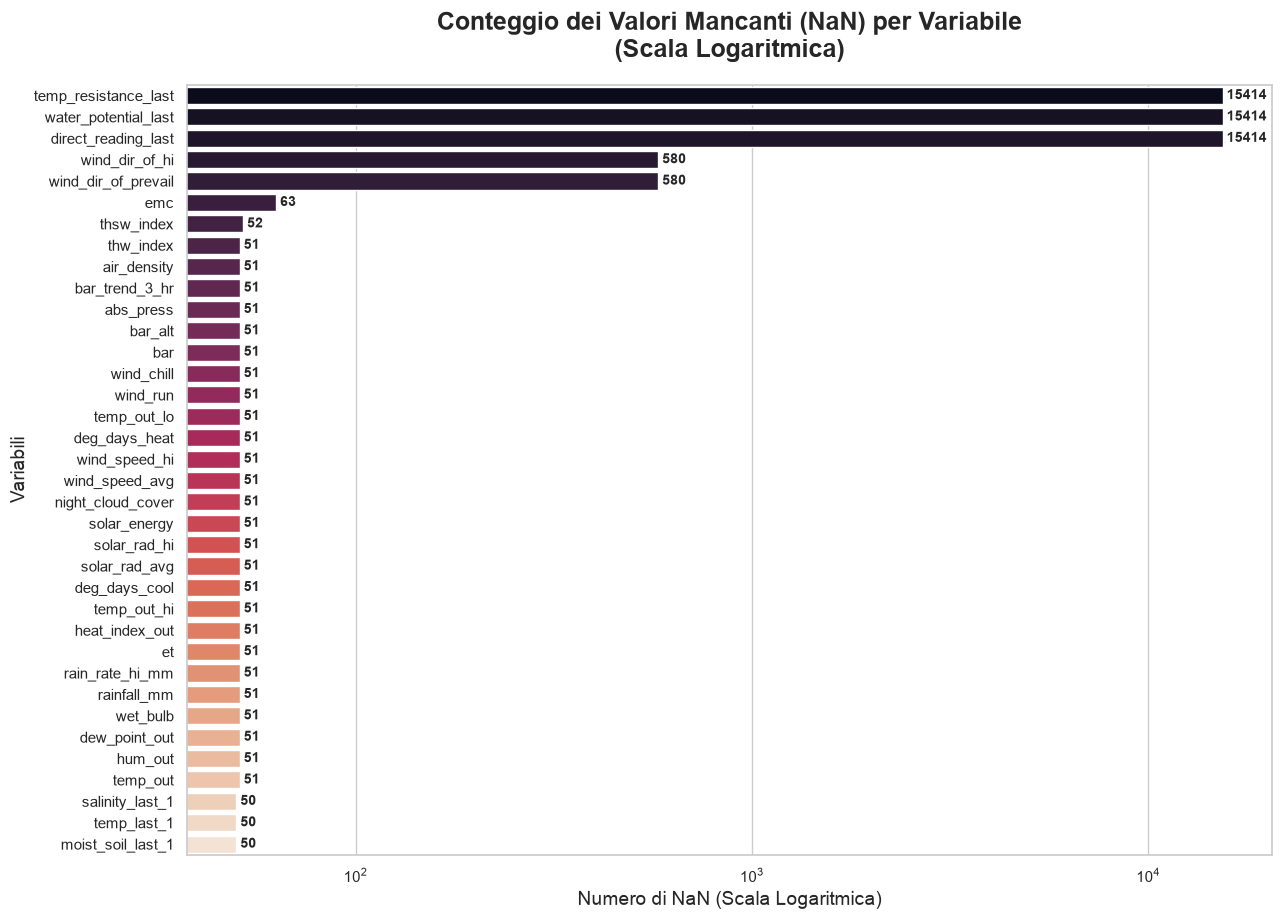

In [10]:
#MISSING VALUES 

total_rows = len(df_train)

# Calcolo esatto dei valori mancanti (NaN) per ogni colonna
nan_counts = df_train.isnull().sum()
nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)
nan_pct = (nan_counts / total_rows) * 100

# Creazione di un DataFrame riassuntivo
nan_summary = pd.DataFrame({
    'Conteggio_NaN': nan_counts, 
    'Percentuale_NaN (%)': nan_pct.round(3)
})

print("--- Riassunto Esatto dei Valori Mancanti (NaN) ---")
print(f"Totale righe nel dataset: {total_rows}\n")
print(nan_summary)

# Generazione di un grafico a barre 
plt.figure(figsize=(14, 10))
sns.set_theme(style="whitegrid")

# Utilizziamo una scala logaritmica per l'asse X a causa dell'enorme differenza tra i sensori rotti (>10k) e quelli con pochi NaN (5)
ax = sns.barplot(x=nan_counts.values, y=nan_counts.index, palette='rocket', hue=nan_counts.index, legend=False)
ax.set_xscale("log")

plt.title("Conteggio dei Valori Mancanti (NaN) per Variabile\n(Scala Logaritmica)", fontsize=18, fontweight='bold', pad=20)
plt.xlabel("Numero di NaN (Scala Logaritmica)", fontsize=14)
plt.ylabel("Variabili", fontsize=14)

# Aggiunta dei valori numerici esatti sulle barre
for i, v in enumerate(nan_counts.values):
    ax.text(v, i, f" {v}", va='center', fontsize=10, fontweight='bold')
plt.show()

Adesso, osserviamo le tre features con tre missing values:

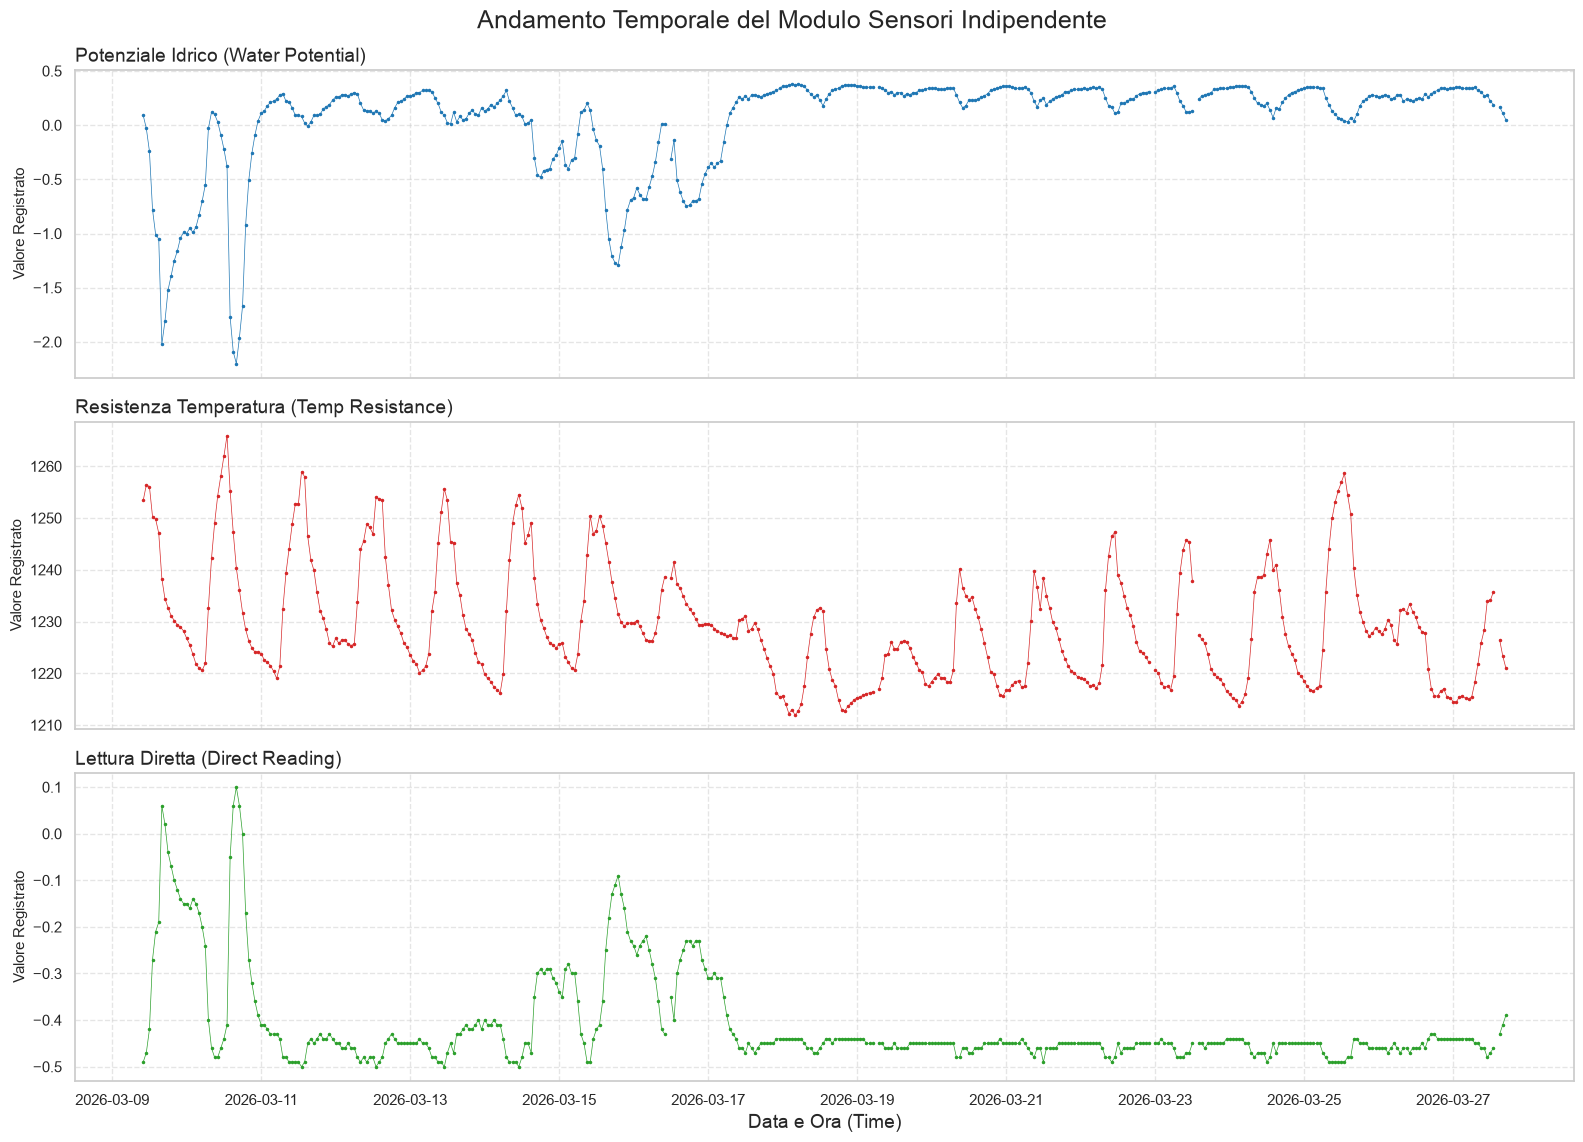

In [11]:

#Definiamo le tre colonne di interesse
colonne_suolo = ['water_potential_last', 'temp_resistance_last', 'direct_reading_last']

# sharex=True assicura che lo zoom temporale sia sincronizzato su tutti e tre i grafici
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(16, 12), sharex=True)


colori = ['#1f77b4', '#d62728', '#2ca02c']
titoli = ['Potenziale Idrico (Water Potential)', 
          'Resistenza Temperatura (Temp Resistance)', 
          'Lettura Diretta (Direct Reading)']

# per popolare ciascun grafico
for i, colonna in enumerate(colonne_suolo):
    
    dati_validi = df_train[colonna]
    
    
    axes[i].plot(dati_validi.index, dati_validi, 
                 color=colori[i], marker='.', linestyle='-', 
                 linewidth=0.5, markersize=3)
    
    # Formattazione del singolo grafico
    axes[i].set_title(titoli[i], fontsize=14, loc='left')
    axes[i].set_ylabel('Valore Registrato', fontsize=11)
    axes[i].grid(True, linestyle='--', alpha=0.5)

#Formattazione generale
plt.suptitle('Andamento Temporale del Modulo Sensori Indipendente', fontsize=18, y=0.95)
plt.xlabel('Data e Ora (Time)', fontsize=14)

# Ottimizza gli spazi tra i grafici per evitare sovrapposizioni di testo
plt.tight_layout()
plt.subplots_adjust(top=0.90) # Lascia spazio per il super-titolo

# Visualizzazione
plt.show()

Il grafico di *direct_reading* è perfettamente speculare a quello del *water_potential*, questo conferma che la *direct_reading* è la grandezza elettrica grezza utilizzata dall'algoritmo della centralina per calcolare il *water_potential*.

Adesso vediamo se tra loro c'è correlazione:


Matrice di correlazione per le variabili sospette di circolarità:
                      water_potential_last  temp_resistance_last  \
water_potential_last              1.000000             -0.308118   
temp_resistance_last             -0.308118              1.000000   
direct_reading_last              -0.953551              0.008516   

                      direct_reading_last  
water_potential_last            -0.953551  
temp_resistance_last             0.008516  
direct_reading_last              1.000000  


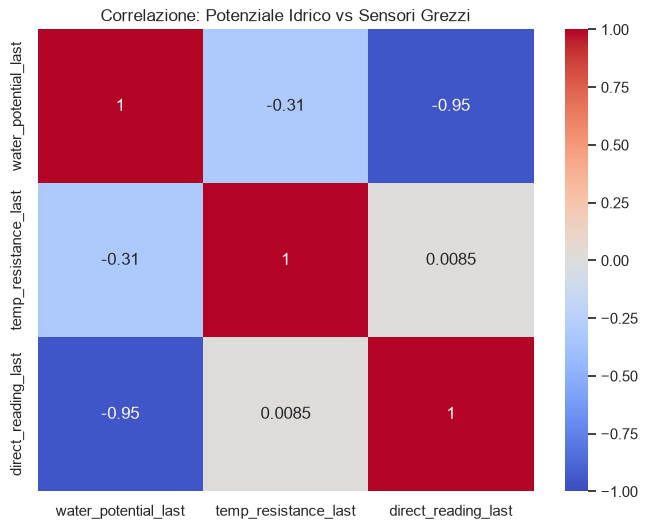

In [12]:
cols_sospette = ['water_potential_last', 'temp_resistance_last', 'direct_reading_last']
correlazione_sospetta = df_train[cols_sospette].corr()
print("\nMatrice di correlazione per le variabili sospette di circolarità:")
print(correlazione_sospetta)
    
plt.figure(figsize=(8, 6))
sns.heatmap(correlazione_sospetta, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlazione: Potenziale Idrico vs Sensori Grezzi")
plt.show()

*direct_reading_last* ha una correlazione negativa alta con *water_potential_last* : -0.995, ciò significa che stanno praticamente misurando la stessa cosa e devo escluderne una altrimenti vado in contro al data leakage.

*temp_resistance_last*  è più ambiguo (corr. -0.51 con *water_potential_last*): probabile che sia la resistenza elettrica grezza da cui, insieme alla temperatura, si deriva il potenziale via calibrazione — quindi è input allo stesso strumento, non una misura indipendente ambientale. Andrebbe escluso anch'esso, a meno che non si sappia con certezza che deriva da un sensore diverso e indipendente, verificarlo dalla tecnica del sensore.


**Soluzione** rimuovo *temp_resistance* e *direct_reading*:

In [13]:
leakage_cols = ['direct_reading_last', 'temp_resistance_last']
df_train = df_train.drop(columns=leakage_cols) 

Adesso voglio studiare gli outliers del mio dataset.

In [14]:
def pulizia_outliers_multimetodo(df):
    """
    Applica metodi di pulizia degli outlier differenziati per dominio agronomico.
    Stampa un report dettagliato delle anomalie rimosse.
    """
    df_train2 = df_train.copy()
    righe_iniziali = len(df_train2)
    report_rimozioni = {}

    # ==========================================
    # 1. LIMITI FISICI (Hard Thresholds)
    # ==========================================
    # Variabili che per le leggi della fisica non possono superare certi valori
    limiti_fisici = {
        'hum_out': (0.0, 100.0),      
        'solar_rad_avg': (0.0, 1400), 
        'bar': (27.0, 32.5),          # Aggiornato per inHg (Pollici di Mercurio)
        'wind_speed_avg': (0.0, 150)  
    }

    for col, (min_val, max_val) in limiti_fisici.items():
        if col in df_train2.columns:
            anomalie = df_train2[(df_train2[col] < min_val) | (df_train2[col] > max_val)]
            if not anomalie.empty:
                df_train2.loc[anomalie.index, col] = np.nan
                report_rimozioni[col] = f"{len(anomalie)} valori fuori limite fisico"

    # ==========================================
    # 2. Z-SCORE (Per distribuzioni normali)
    # ==========================================
    colonne_zscore = ['temp_out', 'temp_out_hi', 'temp_out_lo', 'dew_point_out', 'wet_bulb']
    soglia_z = 3.0

    for col in colonne_zscore:
        if col in df_train2.columns:
            media = df_train2[col].mean()
            std = df_train2[col].std()
            z_scores = np.abs((df_train2[col] - media) / std)
            anomalie = df_train2[z_scores > soglia_z]
            
            if not anomalie.empty:
                df_train2.loc[anomalie.index, col] = np.nan
                report_rimozioni[col] = f"{len(anomalie)} valori oltre {soglia_z} dev. standard"

    # ==========================================
    # 3. IQR (Per distribuzioni asimmetriche tolleranti)
    # ==========================================
    # L'IQR non è influenzato dalla media, quindi è più stabile per variabili rumorose
    colonne_iqr = ['water_potential_last', 'moist_soil_last_1', 'salinity_last_1', 'wind_chill']
    moltiplicatore_iqr = 2.0 # Più è alto, più si è conservativi (si elimina di meno)

    for col in colonne_iqr:
        if col in df_train2.columns:
            Q1 = df_train2[col].quantile(0.25)
            Q3 = df_train2[col].quantile(0.75)
            IQR = Q3 - Q1
            
            limite_inf = Q1 - (moltiplicatore_iqr * IQR)
            limite_sup = Q3 + (moltiplicatore_iqr * IQR)
            
            anomalie = df_train2[(df_train2[col] < limite_inf) | (df_train2[col] > limite_sup)]
            
            if not anomalie.empty:
                df_train2.loc[anomalie.index, col] = np.nan
                report_rimozioni[col] = f"{len(anomalie)} valori fuori dai limiti IQR"

    # ==========================================
    # 4. COLONNE INTOCCABILI
    # ==========================================
    # 'rainfall_mm', 'rain_rate_hi_mm' non vengono toccate perché i picchi sono eventi reali.
    # Eventuali feature cicliche (ora, mese) sono escluse per definizione.

    # ==========================================
    # 5. Gestione dei NaN creati
    # ==========================================
    # Applichiamo l'interpolazione lineare vincolata solo per piccoli gap (max 4 ore)
    df_clean = df_train2.interpolate(method='time', limit=4)
    
    # Report Finale
    print("--- REPORT RIMOZIONE OUTLIER ---")
    if not report_rimozioni:
        print("Nessun outlier estremo rilevato nei parametri definiti.")
    else:
        for col, motivo in report_rimozioni.items():
            print(f"- {col}: {motivo}")
            
    print(f"\nRighe totali analizzate: {righe_iniziali}")
    
    return df_clean

# Esecuzione
df_train = pulizia_outliers_multimetodo(df_train)

--- REPORT RIMOZIONE OUTLIER ---
- dew_point_out: 6 valori oltre 3.0 dev. standard
- water_potential_last: 51 valori fuori dai limiti IQR
- salinity_last_1: 2 valori fuori dai limiti IQR

Righe totali analizzate: 15849


Aver rimosso un totale di 59 valori su 15.849 righe significa aver filtrato appena lo 0,37% del dataset.

Ritorniamo ai missing values adesso:





In [15]:
total_rows = len(df_train)

# Calcolo esatto dei valori mancanti (NaN) per ogni colonna
nan_counts = df_train.isnull().sum()
nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)
nan_pct = (nan_counts / total_rows) * 100

# Creazione di un DataFrame riassuntivo
nan_summary = pd.DataFrame({
    'Conteggio_NaN': nan_counts, 
    'Percentuale_NaN (%)': nan_pct.round(3)
})

print("--- Riassunto Esatto dei Valori Mancanti (NaN) ---")
print(f"Totale righe nel dataset: {total_rows}\n")
print(nan_summary)

--- Riassunto Esatto dei Valori Mancanti (NaN) ---
Totale righe nel dataset: 15849

                      Conteggio_NaN  Percentuale_NaN (%)
water_potential_last          15443               97.438
wind_dir_of_hi                   79                0.498
wind_dir_of_prevail              79                0.498
emc                              46                0.290
solar_energy                     42                0.265
night_cloud_cover                42                0.265
wind_speed_avg                   42                0.265
wind_speed_hi                    42                0.265
wind_run                         42                0.265
solar_rad_avg                    42                0.265
wind_chill                       42                0.265
bar                              42                0.265
bar_alt                          42                0.265
abs_press                        42                0.265
bar_trend_3_hr                   42                0.265
air_

Le variabili *wind_dir_of_hi* e *wind_dir_of_prevail* (direzione del vento) mancano per 79 volte. Questo non è un errore del sensore, ma una legge fisica: quando la velocità del vento (wind_speed) è vicina allo zero (calma piatta), la banderuola dell'anemometro non ha una direzione definibile, e il datalogger registra correttamente un NaN.

La quasi totalità delle variabili meteorologiche (temp_out, hum_out, solar_rad, ecc.) presenta un blocco uniforme di circa 42 valori mancanti.
Questa è un'ottima notizia. Significa che l'hardware della stazione meteo è estremamente solido. Quei 42 buchi corrispondono con ogni probabilità a micro-disconnessioni del datalogger o a riavvii del sistema, che un codice per l'interpolazione gestirà e ricucirà perfettamente senza alcuna perdita di informazione.

Una Rete Neurale LSTM non tollera alcun NaN all'interno dei tensori di addestramento; l'esecuzione del codice andrebbe immediatamente in errore.  
PDF
Le variabili del vento richiedono un trattamento fisico specifico, poiché un NaN causato da "calma piatta" (zero vento)  non deve essere interpolato linearmente, ma forzato a zero o a un valore neutro. Per i restanti 42 buchi meteorologici (dovuti al ricampionamento orario iniziale ), è necessario un passaggio di rammendo finale.

In [16]:
def chiusura_nan_e_vento(df):
    df_clean = df.copy()
    
    # 1. Gestione Fisica del Vento (Sostituisce i NaN con 0 se non c'è vento)
    colonne_vento_dir = ['wind_dir_of_hi', 'wind_dir_of_prevail']
    for col in colonne_vento_dir:
        # Se la velocità è zero, la direzione è ininfluente (impostiamo a -1 o 0)
        df_clean[col] = df_clean[col].fillna(0) 
        
    # 2. Rammendo finale per i 42 micro-vuoti restanti
    # Usiamo l'interpolazione temporale per i buchi brevi. 
    # Qualora ci fossero NaN residui alla primissima riga, usiamo bfill (backward fill)
    df_clean = df_clean.interpolate(method='time', limit=4).bfill().ffill()
    
    return df_clean

# Esecuzione
df_train = chiusura_nan_e_vento(df_train)

# Ragionamento
per via del 91% dei dati mancanti che io voglio addestrare una rete neurale con transfer learning per prevedere piu features

Questo ragionamento si allinea perfettamente con lo stato dell'arte del Semi-Supervised Learning per le serie temporali. Sfruttare il Transfer Learning (o meglio, il Self-Supervised Pretraining) è l'unica via per capitalizzare quel 91% di dati meteorologici orfani del potenziale idrico.

## La Teoria: Come salvare 15.000 righe di dati
### Fase 1: Pretraining Non Supervisionato (l'Autoencoder)
Prendiamo tutte le 15.000 righe di dati (le variabili meteo, VPD, inerzia, ecc.) e nascondiamo del tutto la colonna del potenziale idrico.

Costruiamo una Rete Neurale (tipicamente basata su layer LSTM o GRU, perfetti per le serie temporali) con una struttura a "clessidra" (Autoencoder):
- **Encoder**: Comprime i dati meteo delle ultime 72 ore in uno spazio vettoriale ridotto (Spazio Latente).
- **Decoder**: Cerca di ricostruire esattamente i dati meteo originali partendo da quello spazio compresso.

*Perché lo facciamo?* Addestrando la rete a ricostruire il meteo, costringiamo l'Encoder a imparare le leggi fisiche del vigneto: impara come la temperatura sale dopo l'alba, come il VPD si impenna, come la pioggia abbassa la temperatura. Impara la dinamica, senza bisogno di sapere nulla sul potenziale idrico.

### Fase 2: Transfer Learning e Fine-Tuning (Il Regressore)
Una volta che l'Encoder è diventato "esperto" del clima del vigneto, buttiamo via il Decoder.

Prendiamo l'Encoder pre-addestrato e gli "attacchiamo" in cima un nuovo strato finale (Regressore) progettato per prevedere un solo numero: il potenziale idrico.

A questo punto, addestriamo questa nuova rete solo sulle 1.467 righe in cui il potenziale idrico è noto. Poiché la rete "sa" già come funziona il clima, avrà bisogno di pochissimi dati per capire la correlazione matematica tra le dinamiche meteorologiche (già apprese) e lo stato del suolo.


## Fase 2: Feature Engineering per Reti Neurali
Quando si addestra un modello profondo, in particolare una rete ricorrente (LSTM) per l'analisi di serie storiche, fornire semplicemente i dati grezzi non è sufficiente. È necessario tradurre i concetti fisici e temporali nel "linguaggio matematico" che la rete può comprendere nel modo più efficiente possibile.

Il codice è strutturato in 2 punti:
1. **Codifica ciclica del Tempo**:

     Estrae l'ora (da 0 a 23) e il mese (da 1 a 12) dall'indice temporale e li trasforma in coordinate trigonometriche su una circonferenza unitaria, creando due nuove variabili per l'ora e due per il mese.
 
     **Perché è fondamentale**:

     Le Reti Neurali elaborano i numeri in modo strettamente scalare e lineare. Se fornissimo alla rete l'ora del giorno come un semplice numero intero, essa interpreterebbe le ore 23:00 e le ore 00:00 come temporalmente agli antipodi (essendoci una distanza matematica di 23 unità tra loro). Nella realtà fisica, queste due ore sono adiacenti.
     Scomponendo il tempo in componenti seno e coseno, si mappa la progressione temporale su un cerchio perfetto. In questo spazio vettoriale, le 23:00 e le 00:00 risultano contigue. Questo permette all'architettura LSTM di comprendere senza ambiguità l'andamento dei ritmi circadiani (es. l'escursione termica giorno-notte) e la fenologia stagionale (es. il passaggio da dicembre a gennaio), azzerando le discontinuità di fine ciclo.

2. **Deficit di Pressione di Vapore (VPD)**:
 
     Implementa l'equazione di Tetens per ricavare la pressione di vapore di saturazione (e_s) a partire dalla temperatura dell'aria, e la pressione di vapore attuale (e_a) utilizzando l'umidità relativa. La differenza tra le due restituisce il VPD espresso in kilopascal (kPa).

     **Perché è fondamentale**:
 
     L'umidità relativa (*hum_out*) è un parametro ingannevole in agronomia, poiché dipendente dalla temperatura: l'aria calda può trattenere molta più acqua dell'aria fredda. Il VPD, al contrario, è una misura assoluta della "sete atmosferica".
 
     Se si fornissero alla rete neurale unicamente temperatura e umidità, le si imporrebbe di dedurre e ricostruire da sola le complesse leggi della termodinamica. Calcolando esplicitamente il VPD e fornendolo come feature indipendente, si inietta nel modello una conoscenza di dominio (domain knowledge) formidabile. Il VPD è il reale motore evapotraspirativo: variazioni significative di questo parametro governano la chiusura stomatica della pianta e determinano il progressivo esaurimento dell'acqua nel suolo (ovvero, il potenziale idrico che desideriamo predire).
 


In [18]:
def feature_engineering_lstm(df):
    df_fe = df.copy()
    
    # 1. Codifica Ciclica del Tempo : 
    ora = df_fe.index.hour
    mese = df_fe.index.month
    df_fe['ora_sin'] = np.sin(2 * np.pi * ora / 24.0)
    df_fe['ora_cos'] = np.cos(2 * np.pi * ora / 24.0)
    df_fe['mese_sin'] = np.sin(2 * np.pi * mese / 12.0)
    df_fe['mese_cos'] = np.cos(2 * np.pi * mese / 12.0)
    
    # 2. Deficit di Pressione di Vapore (VPD)
    es = 0.6108 * np.exp((17.27 * df_fe['temp_out']) / (df_fe['temp_out'] + 237.3))
    ea = es * (df_fe['hum_out'] / 100.0)
    df_fe['vpd_kpa'] = es - ea
    
    return df_fe

# Esecuzione indipendente sui due set
df_train = feature_engineering_lstm(df_train)
df_test = feature_engineering_lstm(df_test)

- **VPD (Deficit di Pressione di Vapore)**
     Il VPD rappresenta la "sete" dell'atmosfera. È una misura puramente termodinamica dello stato dell'aria in un dato momento.

     **Definizione**: È la differenza tra la quantità massima di vapore acqueo che l'aria potrebbe trattenere (a una certa temperatura) e la quantità che contiene effettivamente.

     **Unità di misura**: Si misura come una pressione, tipicamente in kilopascal (kPa) o millibar (mbar).

     **Cosa indica**: Misura la forza "estraente" dell'atmosfera. Un VPD pari a 0 kPa significa aria satura (nebbia, 100% di umidità): l'aria non può accogliere altra acqua. Un VPD superiore a 2.0 kPa indica un'aria estremamente secca e calda che "tira" letteralmente l'acqua fuori dalle foglie delle piante.

     **Il Ruolo**: È la forza motrice (il potenziale). Non ti dice quanta acqua si sta muovendo, ma ti dice con quanta aggressività l'aria la sta richiedendo.


- **ET (Evapotraspirazione)**
     L'ET rappresenta l'acqua effettivamente persa dal sistema agricolo. È un flusso materiale, non una pressione.

     **Definizione**: È la somma dell'acqua che evapora fisicamente dalla superficie del suolo nudo (Evaporazione) e dell'acqua che la pianta assorbe dalle radici ed espelle dalle foglie sotto forma di vapore (Traspirazione).

     **Unità di misura**: Si misura come una precipitazione al contrario, tipicamente in millimetri al giorno (mm/giorno) o millimetri all'ora (mm/ora).
 
     **Cosa indica**: Misura la quantità esatta di liquido che ha abbandonato il tuo campo. Se l'ET è di 5 mm, significa che hai perso 5 litri di acqua per ogni metro quadrato di terreno.
 
     **Il Ruolo**: È il risultato dell'azione dell'atmosfera combinata con la risposta della pianta.

Adesso costruiamo il "ponte" tra l'analisi dati tabulare (bidimensionale) e l'architettura di Deep Learning (tridimensionale). 

Per preparare definitivamente i dati per la Rete Neurale LSTM, dobbiamo compiere due operazioni critiche: la Normalizzazione (Scaling) e la Generazione dei Tensori.

In [19]:
from sklearn.preprocessing import MinMaxScaler


def preparazione_dati_lstm(df_train, df_test, target_col='water_potential_last', time_steps=24):
    """
    Esegue la normalizzazione delle feature e trasforma i DataFrame 
    in sequenze tridimensionali per la rete LSTM.
    """
    print(f"Inizio preparazione dati. Finestra temporale impostata a: {time_steps} ore.")

    # ==========================================
    # 1. NORMALIZZAZIONE (Scaling)
    # ==========================================
    # Identifichiamo le colonne feature (escludendo il target)
    features = [col for col in df_train.columns if col != target_col]
    
    # Inizializziamo lo scaler (MinMaxScaler porta i valori tra 0 e 1)
    scaler = MinMaxScaler()
    
    # Copie per non alterare i DataFrame originali
    df_train_scaled = df_train.copy()
    df_test_scaled = df_test.copy()
    
    # FIT & TRANSFORM sul Train set
    df_train_scaled[features] = scaler.fit_transform(df_train[features])
    
    # SOLO TRANSFORM sul Test set (regola d'oro per evitare data leakage)
    df_test_scaled[features] = scaler.transform(df_test[features])
    
    # ==========================================
    # 2. GENERAZIONE DELLE SEQUENZE (Tensori 3D)
    # ==========================================
    def crea_sequenze(df_scaled):
        X, y = [], []
        # Estraiamo le matrici numpy per massimizzare la velocità del ciclo
        X_data = df_scaled[features].values
        y_data = df_scaled[target_col].values
        
        for i in range(len(df_scaled) - time_steps):
            # La sequenza delle ultime 'time_steps' ore
            finestra_temporale = X_data[i:(i + time_steps)]
            # Il target corrispondente all'ora successiva alla finestra
            target_futuro = y_data[i + time_steps]
            
            X.append(finestra_temporale)
            y.append(target_futuro)
            
        return np.array(X), np.array(y)
    
    # Creazione sequenze per Train e Test
    X_train_seq, y_train_seq = crea_sequenze(df_train_scaled)
    X_test_seq, y_test_seq = crea_sequenze(df_test_scaled)
    
    print("\n--- Dimensioni dei Tensori Generati ---")
    print(f"X_train_seq (Features): {X_train_seq.shape}")
    print(f"y_train_seq (Target)  : {y_train_seq.shape}")
    print(f"X_test_seq  (Features): {X_test_seq.shape}")
    
    return X_train_seq, y_train_seq, X_test_seq, y_test_seq, scaler, features

# Esecuzione (scegliamo inizialmente una finestra di 24 ore)
X_train, y_train, X_test, y_test, scaler_X, lista_features = preparazione_dati_lstm(df_train_fe, df_test_fe, time_steps=24)

Inizio preparazione dati. Finestra temporale impostata a: 24 ore.

--- Dimensioni dei Tensori Generati ---
X_train_seq (Features): (15825, 24, 38)
y_train_seq (Target)  : (15825,)
X_test_seq  (Features): (1058, 24, 38)
